# 07 — Otimização de Hiperparâmetros (Nested CV no nível de AMOSTRA)

## Fluxo
```
Para cada pré-processamento com sua config do notebook 06:

  Outer StratifiedKFold k=3 (sobre as 19 amostras)
    └─ Para cada fold externo:
         → Pré-processamento ajustado no TREINO (sem leakage)
         → Seleção de bandas no TREINO
         → Gold no nível de amostra
         → GridSearchCV com StratifiedKFold k=2 (inner)
         → Avaliação no teste externo do fold (~6 amostras)

  Melhores params = fold com maior F1 no CV interno
  Métricas externas = média dos 3 folds externos
```
> **Alteração vs. plano**: o inner cai de k=5 para k=2 porque, com apenas 3
> resistentes, o treino externo tem 2 positivas (k máximo = 2). Documentado
> junto ao k=5→k=3 do parcial.
>
> Com N=19 a otimização é **exploratória** — a alta variância entre folds
> (ver abaixo) mostra que os "melhores" params não são estáveis. A métrica
> honesta de desempenho vem do K-Fold k=3 + permutação no NB08.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import warnings
warnings.filterwarnings("ignore")

ROOT_DIR = Path("..").resolve()
sys.path.append(str(ROOT_DIR))
sys.path.append(str(ROOT_DIR / "src"))

# Tuner e grades no nível de AMOSTRA (nested CV: outer StratifiedKFold k=3, inner k=2).
# As grades foram movidas de hyperparameter_tuner.py (removido) para modeling_roi.py.
from src.modeling_roi import (
    load_roi_matrix,
    otimizar_hiperparametros_roi,
    PARAM_GRID_REDUZIDA,
    PARAM_GRID_COMPLETA,
)
from src.feature_engineering import build_gold_matrix
from src.feature_selectors import selecionar_bandas_consenso

print("Imports OK")

Imports OK


## Configuração

Cada pré-processamento usa uma config de seleção/features (definida em `CONFIGS_POR_PRE`).
A otimização varre a grade `PARAM_GRID_REDUZIDA` e salva os melhores params em
`config_pre_{PRE}.json`, consumidos pelo NB08.

> As métricas de F1/AUC aqui são **internas ao tuning** (StratifiedKFold k=3 com
> ~6 amostras por fold) e servem só para escolher params — não são a métrica
> final. O desempenho honesto está no NB08 (K-Fold k=3 + permutação).

In [2]:
OUTPUT_DIR  = ROOT_DIR / "data" / "gold level" / "features_extraidas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

K_BANDAS = 15
GRADE    = PARAM_GRID_REDUZIDA

# Mapeia nome de exibição → chave de pré-processamento do modeling_roi
_MAP_PRE = {"RAW": "raw", "MSC": "msc", "SavGol": "savigol", "ZScore": "z_score"}

# Config por pré-processamento (seleção de bandas + features derivadas)
CONFIGS_POR_PRE = {
    "MSC":    {"metodo_pre": "msc",     "metodo_selecao": "mi",   "incluir_features_derivadas": False},
    "RAW":    {"metodo_pre": "raw",     "metodo_selecao": None,   "incluir_features_derivadas": True},
    "SavGol": {"metodo_pre": "savigol", "metodo_selecao": None,   "incluir_features_derivadas": True},
    "ZScore": {"metodo_pre": "z_score", "metodo_selecao": "mi",   "incluir_features_derivadas": False},
}

# Matriz ROI (espectro médio por amostra) — pré-proc aplicado dentro do fold
df_roi = load_roi_matrix()
PRE_VIZ = "MSC"

n_pos = int(df_roi['target'].sum())
print(f"Matriz ROI : {df_roi['sample_id'].nunique()} amostras "
      f"({n_pos} resistentes) × {df_roi.shape[1]-2} bandas")
print(f"Viz        : {PRE_VIZ}")

import itertools
n_comb = sum(1 for _ in itertools.product(*GRADE.values()))
print(f"\nGrade      : {n_comb} combos × 2 inner × 3 outer = {n_comb*6} fits por pré-processamento")
print(f"Total      : {n_comb*6*4} fits (4 pré-processamentos)")

Matriz ROI : 19 amostras (3 resistentes) × 226 bandas
Viz        : MSC

Grade      : 256 combos × 2 inner × 3 outer = 1536 fits por pré-processamento
Total      : 6144 fits (4 pré-processamentos)


## Grade de hiperparâmetros

In [3]:
print("Parâmetros a otimizar:")
for param, valores in GRADE.items():
    print(f"  {param:20s}: {valores}")

Parâmetros a otimizar:
  boosting_type       : ['gbdt', 'dart']
  num_leaves          : [7, 31]
  max_depth           : [3, -1]
  learning_rate       : [0.01, 0.1]
  feature_fraction    : [0.7, 1.0]
  lambda_l1           : [0.0, 1.0]
  lambda_l2           : [0.1, 1.0]
  min_child_samples   : [2, 10]


## Executar Grid Search

In [4]:
# Grid Search para MSC (visualização exploratória — células seguintes)
cfg_viz = CONFIGS_POR_PRE[PRE_VIZ]
resultado = otimizar_hiperparametros_roi(
    df_roi                     = df_roi,
    metodo_pre                 = cfg_viz["metodo_pre"],
    metodo_selecao             = cfg_viz["metodo_selecao"],
    k_bandas                   = K_BANDAS,
    param_grid                 = GRADE,
    incluir_features_derivadas = cfg_viz["incluir_features_derivadas"],
    verbose                    = True,
)

  Fold externo 1/3 (treino 12 am., teste 7 am., inner k=2): F1cv=1.000 | F1ext=0.000 | AUCext=0.500


  Fold externo 2/3 (treino 13 am., teste 6 am., inner k=2): F1cv=0.286 | F1ext=0.000 | AUCext=0.600


  Fold externo 3/3 (treino 13 am., teste 6 am., inner k=2): F1cv=0.750 | F1ext=0.667 | AUCext=1.000

  Melhores params (fold 1, F1cv=1.000): {'boosting_type': 'gbdt', 'feature_fraction': 0.7, 'lambda_l1': 0.0, 'lambda_l2': 0.1, 'learning_rate': 0.01, 'max_depth': 3, 'min_child_samples': 2, 'num_leaves': 7}
  Métricas externas médias: F1=0.222 ± 0.385 | AUC=0.700


## Top combinações do CV interno

In [5]:
df_cv = resultado['df_cv_resultados'].copy()
df_cv.columns = [c.replace('param_','') for c in df_cv.columns]
df_cv = df_cv.rename(columns={
    'mean_test_score': 'F1 médio (CV)',
    'std_test_score':  'F1 std',
    'rank_test_score': 'Rank',
})
print("Top 15 combinações:")
display(df_cv.head(15).round(4))

Top 15 combinações:


,boosting_type,feature_fraction,lambda_l1,lambda_l2,learning_rate,max_depth,min_child_samples,num_leaves,F1 médio (CV),F1 std,Rank
0,gbdt,0.7,0.0,0.1,0.01,3,2,7,1.0,0.0,1
1,gbdt,0.7,0.0,0.1,0.01,3,2,31,1.0,0.0,1
2,gbdt,0.7,0.0,0.1,0.01,-1,2,31,1.0,0.0,1
3,gbdt,0.7,0.0,0.1,0.01,-1,2,7,1.0,0.0,1
4,gbdt,0.7,0.0,0.1,0.10,-1,2,7,1.0,0.0,1
5,gbdt,0.7,0.0,0.1,0.10,-1,2,31,1.0,0.0,1
6,gbdt,0.7,0.0,0.1,0.10,3,2,31,1.0,0.0,1
7,gbdt,0.7,0.0,0.1,0.10,3,2,7,1.0,0.0,1
8,gbdt,0.7,0.0,1.0,0.10,3,2,7,1.0,0.0,1
9,gbdt,0.7,0.0,1.0,0.10,3,2,31,1.0,0.0,1


## Melhores hiperparâmetros e métricas finais

In [6]:
print("═" * 55)
print("MELHORES HIPERPARÂMETROS (fold com maior F1 CV interno)")
print("═" * 55)
for k, v in resultado['melhores_params'].items():
    print(f"  {k:20s}: {v}")
print(f"  {'F1 CV interno':20s}: {resultado['melhor_score_cv']:.4f}")

print("\n" + "═" * 55)
print("MÉTRICAS EXTERNAS POR FOLD")
print("═" * 55)
for i, (met, score_cv) in enumerate(zip(resultado['metricas_por_fold'],
                                         resultado['scores_cv_por_fold'])):
    print(f"  Fold {i+1} (F1_cv={score_cv:.4f}): "
          f"F1={met['F1-score']:.4f} | AUC={met['ROC-AUC']:.4f} | Recall={met['Recall']:.4f}")

print("\n" + "═" * 55)
print("MÉTRICAS EXTERNAS — MÉDIA DOS 3 FOLDS")
print("═" * 55)
ag = resultado['metricas_agregadas']
for nome in ['F1-score', 'ROC-AUC', 'Recall', 'Precisão', 'Acurácia']:
    std = ag.get(f"{nome} (std)", 0)
    print(f"  {nome:12s}: {ag[nome]:.4f} ± {std:.4f}")


═══════════════════════════════════════════════════════
MELHORES HIPERPARÂMETROS (fold com maior F1 CV interno)
═══════════════════════════════════════════════════════
  boosting_type       : gbdt
  feature_fraction    : 0.7
  lambda_l1           : 0.0
  lambda_l2           : 0.1
  learning_rate       : 0.01
  max_depth           : 3
  min_child_samples   : 2
  num_leaves          : 7
  F1 CV interno       : 1.0000

═══════════════════════════════════════════════════════
MÉTRICAS EXTERNAS POR FOLD
═══════════════════════════════════════════════════════
  Fold 1 (F1_cv=1.0000): F1=0.0000 | AUC=0.5000 | Recall=0.0000
  Fold 2 (F1_cv=0.2857): F1=0.0000 | AUC=0.6000 | Recall=0.0000
  Fold 3 (F1_cv=0.7500): F1=0.6667 | AUC=1.0000 | Recall=1.0000

═══════════════════════════════════════════════════════
MÉTRICAS EXTERNAS — MÉDIA DOS 3 FOLDS
═══════════════════════════════════════════════════════
  F1-score    : 0.2222 ± 0.3849
  ROC-AUC     : 0.7000 ± 0.2646
  Recall      : 0.3333 ± 0.5774
  

## Feature Importance do modelo otimizado

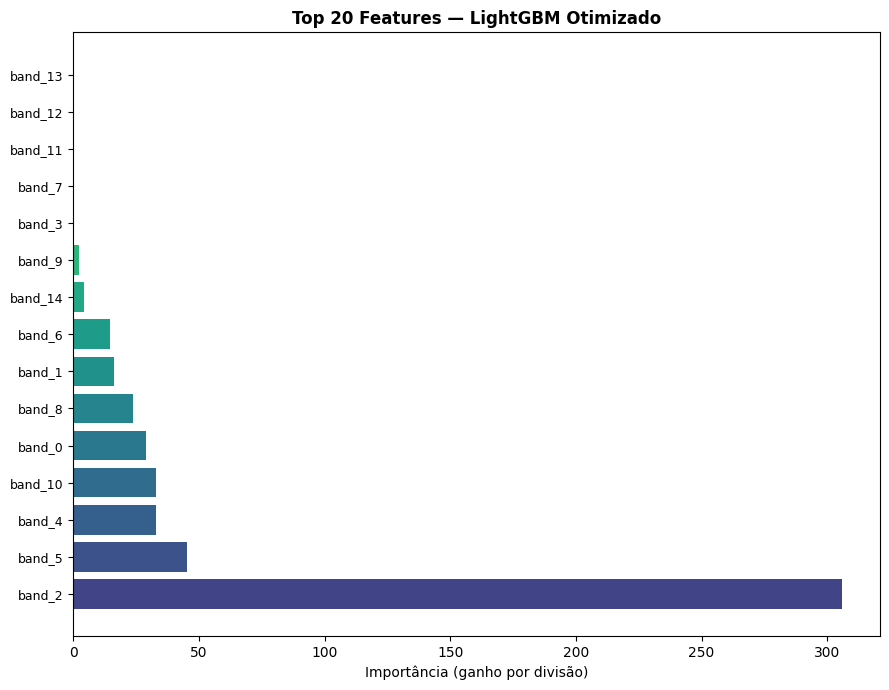


Top 10:


,feature,importance,rank
0,band_2,305.718109,1
1,band_5,45.092010,2
2,band_4,33.004870,3
3,band_10,32.993490,4
4,band_0,29.041910,5
5,band_8,23.703099,6
6,band_1,16.164660,7
7,band_6,14.596610,8
8,band_14,4.417510,9
9,band_9,2.382960,10


In [7]:
model_final   = resultado['grid_search'].best_estimator_
feature_names = resultado['feature_names']

df_fi = pd.DataFrame({
    'feature':    feature_names,
    'importance': model_final.feature_importances_,
}).sort_values('importance', ascending=False).reset_index(drop=True)
df_fi['rank'] = df_fi.index + 1

top_fi = df_fi.head(20)
fig, ax = plt.subplots(figsize=(9, 7))
cores = cm.viridis(np.linspace(0.2, 0.9, len(top_fi)))
ax.barh(range(len(top_fi)), top_fi['importance'].values[::-1], color=cores[::-1])
ax.set_yticks(range(len(top_fi)))
ax.set_yticklabels(top_fi['feature'].values[::-1], fontsize=9)
ax.set_xlabel('Importância (ganho por divisão)')
ax.set_title('Top 20 Features — LightGBM Otimizado', fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("feature_importance_otimizado.png", dpi=120, bbox_inches='tight')
plt.show()
print("\nTop 10:")
display(df_fi.head(10))

## Loop — Grid Search para todos os pré-processamentos

In [8]:
import json as _json

resultados_07 = {}

for nome_pre, cfg in CONFIGS_POR_PRE.items():
    print(f"\n{'='*55}")
    print(f"[{nome_pre}] pre={cfg['metodo_pre']} | selecao={cfg['metodo_selecao']} "
          f"| derivadas={cfg['incluir_features_derivadas']}")

    caminho_json = OUTPUT_DIR / f"config_pre_{nome_pre}.json"
    if caminho_json.exists():
        print(f"  [SKIP] {caminho_json.name} já existe")
        with open(caminho_json) as f:
            resultados_07[nome_pre] = _json.load(f)
        continue

    res = otimizar_hiperparametros_roi(
        df_roi                     = df_roi,
        metodo_pre                 = cfg["metodo_pre"],
        metodo_selecao             = cfg["metodo_selecao"],
        k_bandas                   = K_BANDAS,
        param_grid                 = GRADE,
        incluir_features_derivadas = cfg["incluir_features_derivadas"],
        verbose                    = True,
    )

    config_json = {
        "pre_proc":                    nome_pre,
        "metodo_pre":                  cfg["metodo_pre"],
        "metodo_selecao":              str(cfg["metodo_selecao"]),
        "k_bandas":                    K_BANDAS,
        "incluir_features_derivadas":  cfg["incluir_features_derivadas"],
        "melhores_params": {
            k: (v if not isinstance(v, np.generic) else v.item())
            for k, v in res["melhores_params"].items()
        },
        "bandas":         res["bandas"],
        "metricas_cv":          float(res["melhor_score_cv"]),
        "metricas_teste":       {k: float(v) for k, v in res["metricas_teste"].items()},
        "metricas_agregadas":   {k: float(v) for k, v in res["metricas_agregadas"].items()},
        "params_por_fold":      res["params_por_fold"],
        "scores_cv_por_fold":   [float(s) for s in res["scores_cv_por_fold"]],
    }

    with open(caminho_json, "w", encoding="utf-8") as f:
        _json.dump(config_json, f, indent=2, ensure_ascii=False)

    resultados_07[nome_pre] = config_json
    print(f"  Salvo: {caminho_json.name}")
    print(f"  F1 CV interno : {res['melhor_score_cv']:.4f}")
    print(f"  F1 teste      : {res['metricas_teste']['F1-score']:.4f}")

print("\n[OK] Configs salvas para todos os pré-processamentos.")
print("\nResumo dos melhores hiperparâmetros:")
for pre, cfg_json in resultados_07.items():
    print(f"\n  {pre}: F1_cv={cfg_json['metricas_cv']:.4f}")
    for k, v in cfg_json["melhores_params"].items():
        print(f"    {k:20s}: {v}")


[MSC] pre=msc | selecao=mi | derivadas=False
  [SKIP] config_pre_MSC.json já existe

[RAW] pre=raw | selecao=None | derivadas=True
  [SKIP] config_pre_RAW.json já existe

[SavGol] pre=savigol | selecao=None | derivadas=True
  [SKIP] config_pre_SavGol.json já existe

[ZScore] pre=z_score | selecao=mi | derivadas=False
  [SKIP] config_pre_ZScore.json já existe

[OK] Configs salvas para todos os pré-processamentos.

Resumo dos melhores hiperparâmetros:

  MSC: F1_cv=1.0000
    boosting_type       : gbdt
    feature_fraction    : 0.7
    lambda_l1           : 0.0
    lambda_l2           : 0.1
    learning_rate       : 0.01
    max_depth           : 3
    min_child_samples   : 2
    num_leaves          : 7

  RAW: F1_cv=0.3333
    boosting_type       : gbdt
    feature_fraction    : 0.7
    lambda_l1           : 0.0
    lambda_l2           : 0.1
    learning_rate       : 0.01
    max_depth           : 3
    min_child_samples   : 2
    num_leaves          : 7

  SavGol: F1_cv=0.1429
    boo

## Visualização dos hiperparâmetros otimizados

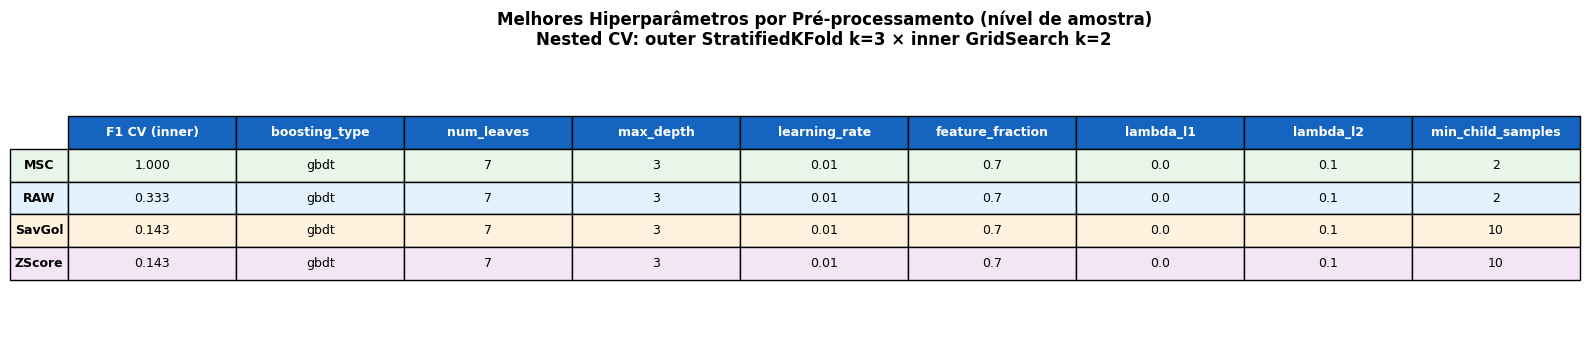

Figura salva: hyperparametros_tabela.png


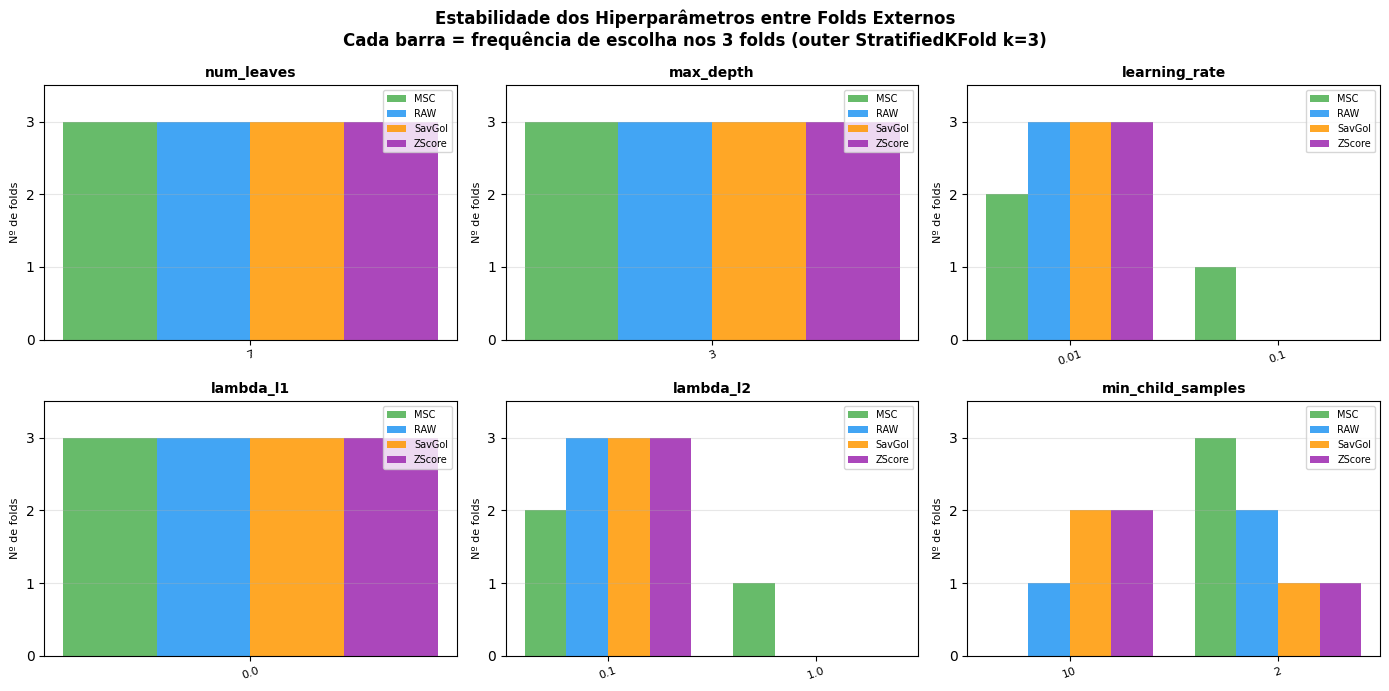

Figura salva: hyperparametros_estabilidade.png


In [9]:
# ── Tabela comparativa dos hiperparâmetros por pré-processamento ─────────────
# Lê os JSONs salvos e gera duas figuras para slides:
#   1. Tabela dos melhores parâmetros + F1 CV interno por pré-processamento
#   2. Heatmap mostrando como os parâmetros variaram entre folds (instabilidade)

import json as _json, matplotlib.pyplot as plt, numpy as np, pandas as pd
from pathlib import Path

OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"
PRE_PROCS  = ["MSC", "RAW", "SavGol", "ZScore"]

# Carrega JSONs
cfgs = {}
for pre in PRE_PROCS:
    p = OUTPUT_DIR / f"config_pre_{pre}.json"
    if p.exists():
        with open(p) as f:
            cfgs[pre] = _json.load(f)

if not cfgs:
    print("Nenhum JSON encontrado. Rode a célula do loop primeiro.")
else:
    PARAMS_SHOW = [
        "boosting_type", "num_leaves", "max_depth",
        "learning_rate", "feature_fraction",
        "lambda_l1", "lambda_l2", "min_child_samples",
    ]

    # ── Figura 1: Tabela de melhores parâmetros ───────────────────────────────
    rows = []
    for pre in PRE_PROCS:
        if pre not in cfgs: continue
        cfg = cfgs[pre]
        row = {"Pré-proc": pre, "F1 CV (inner)": f"{cfg['metricas_cv']:.3f}"}
        for p in PARAMS_SHOW:
            row[p] = str(cfg["melhores_params"].get(p, "—"))
        rows.append(row)

    df_tab = pd.DataFrame(rows).set_index("Pré-proc")
    cols_tabela = ["F1 CV (inner)"] + PARAMS_SHOW

    fig1, ax1 = plt.subplots(figsize=(16, 3.5))
    ax1.axis("off")

    cores_pre = {"MSC": "#E8F5E9", "RAW": "#E3F2FD",
                 "SavGol": "#FFF3E0", "ZScore": "#F3E5F5"}
    cell_text  = [[str(df_tab.loc[pre, c]) for c in cols_tabela]
                  for pre in df_tab.index]
    row_colors = [[cores_pre.get(pre, "#FFFFFF")] * len(cols_tabela)
                  for pre in df_tab.index]

    tbl = ax1.table(
        cellText=cell_text,
        rowLabels=list(df_tab.index),
        colLabels=cols_tabela,
        cellLoc="center", rowLoc="center", loc="center",
        cellColours=row_colors,
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1, 2.0)

    for j in range(len(cols_tabela)):
        tbl[(0, j)].set_facecolor("#1565C0")
        tbl[(0, j)].set_text_props(color="white", fontweight="bold")
    for i in range(len(df_tab.index)):
        tbl[(i+1, -1)].set_facecolor(cores_pre.get(df_tab.index[i], "#FFF"))
        tbl[(i+1, -1)].set_text_props(fontweight="bold")

    ax1.set_title(
        "Melhores Hiperparâmetros por Pré-processamento (nível de amostra)\n"
        "Nested CV: outer StratifiedKFold k=3 × inner GridSearch k=2",
        fontsize=12, fontweight="bold", pad=15
    )
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "hyperparametros_tabela.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Figura salva: hyperparametros_tabela.png")

    # ── Figura 2: Instabilidade dos parâmetros entre os 3 folds externos ─────
    PARAMS_NUM = ["num_leaves", "max_depth", "learning_rate",
                  "lambda_l1", "lambda_l2", "min_child_samples"]

    fig2, axes2 = plt.subplots(2, 3, figsize=(14, 7))
    fig2.suptitle(
        "Estabilidade dos Hiperparâmetros entre Folds Externos\n"
        "Cada barra = frequência de escolha nos 3 folds (outer StratifiedKFold k=3)",
        fontsize=12, fontweight="bold"
    )

    cores_list = ["#4CAF50", "#2196F3", "#FF9800", "#9C27B0"]

    for ax, param in zip(axes2.flat, PARAMS_NUM):
        all_values = set()
        for pre in PRE_PROCS:
            if pre not in cfgs: continue
            for fold_params in cfgs[pre].get("params_por_fold", []):
                all_values.add(str(fold_params.get(param, "—")))
        all_values = sorted(all_values)
        x = np.arange(len(all_values))
        width = 0.2

        for j, (pre, cor) in enumerate(zip(PRE_PROCS, cores_list)):
            if pre not in cfgs: continue
            folds = cfgs[pre].get("params_por_fold", [])
            contagem = {v: 0 for v in all_values}
            for fp in folds:
                v = str(fp.get(param, "—"))
                if v in contagem:
                    contagem[v] += 1
            vals = [contagem[v] for v in all_values]
            ax.bar(x + j * width, vals, width, label=pre, color=cor, alpha=0.85)

        ax.set_title(param, fontweight="bold", fontsize=10)
        ax.set_xticks(x + width * 1.5)
        ax.set_xticklabels(all_values, fontsize=8, rotation=20)
        ax.set_ylabel("Nº de folds", fontsize=8)
        ax.set_yticks([0, 1, 2, 3])
        ax.set_ylim(0, 3.5)
        ax.grid(axis="y", alpha=0.3)
        ax.legend(fontsize=7)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "hyperparametros_estabilidade.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Figura salva: hyperparametros_estabilidade.png")